<a href="https://colab.research.google.com/github/aadeshbhamare/DataScience-Week2---WeIntern-Project/blob/main/notebooks/Task_02_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# DATA ANALYSIS LIBRARIES
import os
import pandas as pd
import numpy as np
# VISUALIZATION LIBRARIES
import matplotlib.pyplot as plt
import seaborn as sns
# WARNINGS
import warnings
warnings.filterwarnings("ignore")
# DISPLAY SETTINGS
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)
# VISUALIZATION SETTINGS
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# GITHUB DATASET PATH
BASE_URL = "https://raw.githubusercontent.com/aadeshbhamare/DataScience-Week2---WeIntern-Project/main/data/cleaned/"
# LOAD CLEANED DATASETS
train_clean = pd.read_csv(
    BASE_URL + "cleaned_train.csv",
    parse_dates=["date"]
)
store_clean = pd.read_csv(
    BASE_URL + "cleaned_store.csv"
)
# DATASET SHAPES
print("Train Dataset Shape:", train_clean.shape)
print("Store Dataset Shape:", store_clean.shape)
print("\nDatasets loaded successfully!")

Train Dataset Shape: (1017209, 9)
Store Dataset Shape: (1115, 13)

Datasets loaded successfully!


In [ ]:
# MERGE TRAIN AND STORE DATASETS
eda_df = pd.merge(
    train_clean,
    store_clean,
    on="store",
    how="left",
    validate="many_to_one"
)
# DISPLAY MERGED DATASET
print("Merged Dataset Shape:", eda_df.shape)
display(eda_df.head())
print("\nMissing Values:", eda_df.isnull().sum().sum())
print("\nMerge completed successfully!")

Merged Dataset Shape: (1017209, 21)


,store,dayofweek,date,sales,customers,open,promo,stateholiday,schoolholiday,storetype,assortment,competitiondistance,competitionopensincemonth,competitionopensinceyear,promo2,promo2sinceweek,promo2sinceyear,promointerval,competitiondistance_missing,promo2_not_applicable,competition_opening_info_missing
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.00,9,2008,0,0,0,No Promo2,0,1,0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11,2007,1,13,2010,"Jan,Apr,Jul,Oct",0,0,0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.00,12,2006,1,14,2011,"Jan,Apr,Jul,Oct",0,0,0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9,2009,0,0,0,No Promo2,0,1,0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.00,4,2015,0,0,0,No Promo2,0,1,0



Missing Values: 0

Merge completed successfully!


In [ ]:
# SECTION 4.1 - NUMERICAL DESCRIPTIVE STATISTICS

numerical_columns = eda_df.select_dtypes(
    include=np.number
).columns.tolist()

numerical_summary = eda_df[numerical_columns].describe().T

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max
store,1017209.00,558.43,321.91,1.00,280.00,558.00,838.00,1115.00
dayofweek,1017209.00,4.00,2.00,1.00,2.00,4.00,6.00,7.00
sales,1017209.00,5773.82,3849.93,0.00,3727.00,5744.00,7856.00,41551.00
customers,1017209.00,633.15,464.41,0.00,405.00,609.00,837.00,7388.00
open,1017209.00,0.83,0.38,0.00,1.00,1.00,1.00,1.00
promo,1017209.00,0.38,0.49,0.00,0.00,0.00,1.00,1.00
schoolholiday,1017209.00,0.18,0.38,0.00,0.00,0.00,0.00,1.00
competitiondistance,1017209.00,5422.02,7706.92,20.00,710.00,2325.00,6880.00,75860.00
competitionopensincemonth,1017209.00,4.93,4.28,0.00,0.00,4.00,9.00,12.00
competitionopensinceyear,1017209.00,1370.17,935.36,0.00,0.00,2006.00,2011.00,2015.00


In [ ]:
# SECTION 4.2 - CATEGORICAL DESCRIPTIVE STATISTICS

categorical_columns = eda_df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

categorical_summary = eda_df[categorical_columns].describe().T

display(categorical_summary)

,count,unique,top,freq
stateholiday,1017209,5,0,855087
storetype,1017209,4,a,551627
assortment,1017209,3,a,537445
promointerval,1017209,4,No Promo2,508031


In [ ]:
# SECTION 4.3 - SALES AND CUSTOMERS SUMMARY

sales_summary = eda_df[
    ["sales", "customers"]
].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
]).T

display(sales_summary)

,count,mean,median,std,min,max
sales,1017209.00,5773.82,5744.00,3849.93,0.00,41551.00
customers,1017209.00,633.15,609.00,464.41,0.00,7388.00


In [ ]:
# SECTION 4.4 - STORE-WISE SALES SUMMARY

store_sales_summary = (
    eda_df.groupby("store")["sales"]
    .agg(["count", "mean", "median", "sum", "min", "max"])
    .sort_values("mean", ascending=False)
)

display(store_sales_summary.head(10))

,count,mean,median,sum,min,max
store,,,,,,
262,942,20718.52,19415.50,19516842,13210,38722
817,942,18108.14,20914.00,17057867,0,38025
562,942,17969.56,18029.50,16927322,8498,28680
1114,942,17200.20,19556.50,16202585,0,35697
251,942,15814.09,17640.00,14896870,0,35350
842,758,15242.11,17375.50,11553523,0,35154
513,942,15129.94,17032.00,14252406,0,31094
788,942,14949.19,16549.00,14082141,0,32170
733,942,14933.29,14795.50,14067158,6838,22137


In [ ]:
# SECTION 4.5 - DAY-WISE SALES SUMMARY

day_sales_summary = (
    eda_df.groupby("dayofweek")["sales"]
    .agg(["mean", "median", "sum", "count"])
    .sort_values("mean", ascending=False)
)

display(day_sales_summary)

,mean,median,sum,count
dayofweek,,,,
1,7809.04,7310.00,1130203012,144730
2,7005.24,6463.00,1020411930,145664
5,6723.27,6434.00,980555941,145845
3,6555.88,6133.00,954962863,145665
4,6247.58,6020.00,911177709,145845
6,5847.56,5410.00,846317735,144730
7,204.18,0.00,29551433,144730


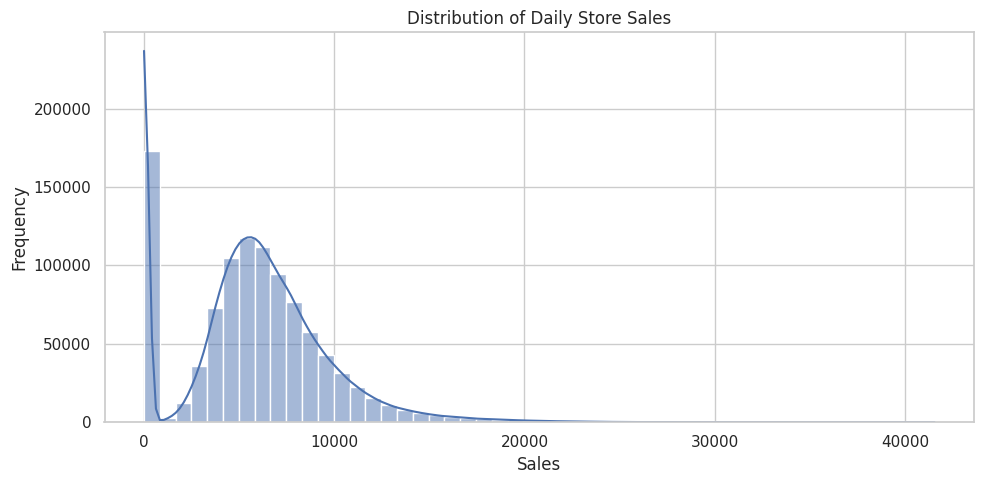

In [ ]:
# SECTION 5.1 - SALES DISTRIBUTION

plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="sales",
    bins=50,
    kde=True
)

plt.title("Distribution of Daily Store Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

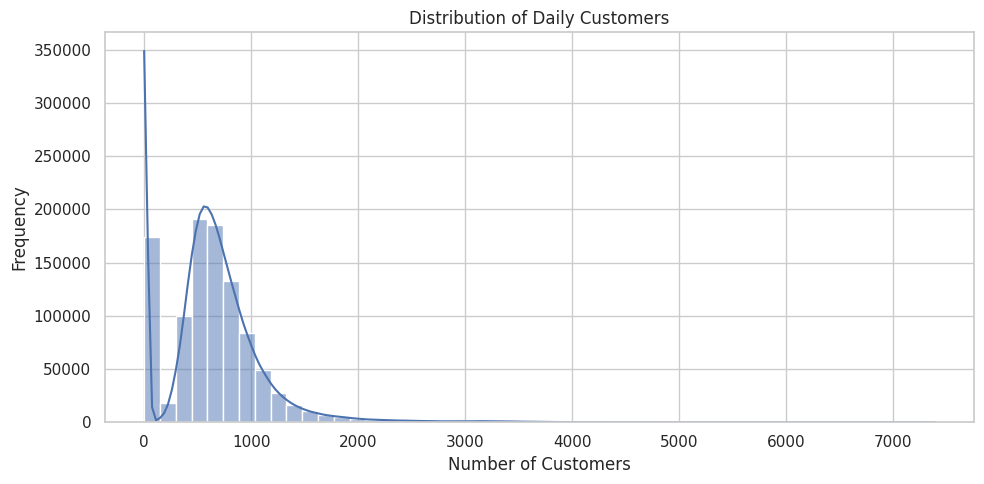

In [ ]:
# SECTION 5.2 - CUSTOMERS DISTRIBUTION

plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="customers",
    bins=50,
    kde=True
)

plt.title("Distribution of Daily Customers")
plt.xlabel("Number of Customers")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

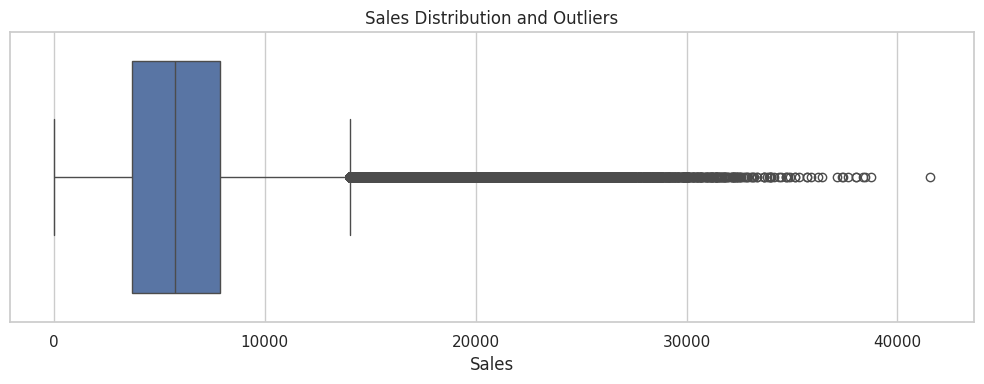

In [ ]:
# SECTION 5.3 - SALES BOXPLOT

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=eda_df["sales"]
)

plt.title("Sales Distribution and Outliers")
plt.xlabel("Sales")
plt.tight_layout()
plt.show()

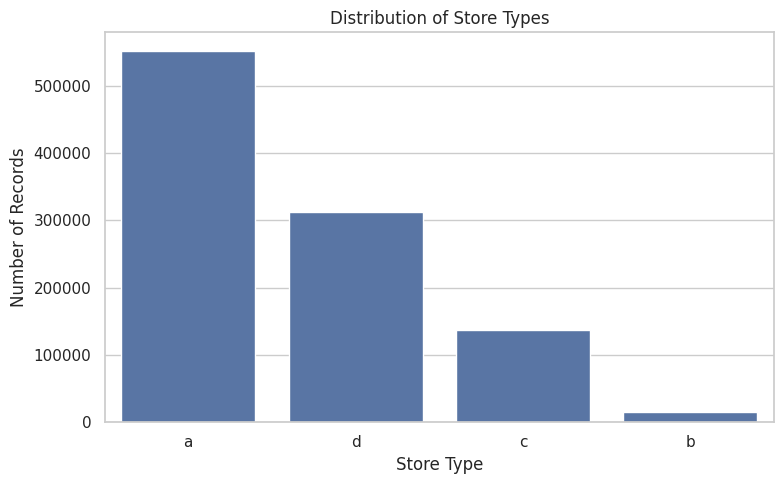

In [ ]:
# SECTION 5.4 - STORE TYPE DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.countplot(
    data=eda_df,
    x="storetype",
    order=eda_df["storetype"].value_counts().index
)

plt.title("Distribution of Store Types")
plt.xlabel("Store Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

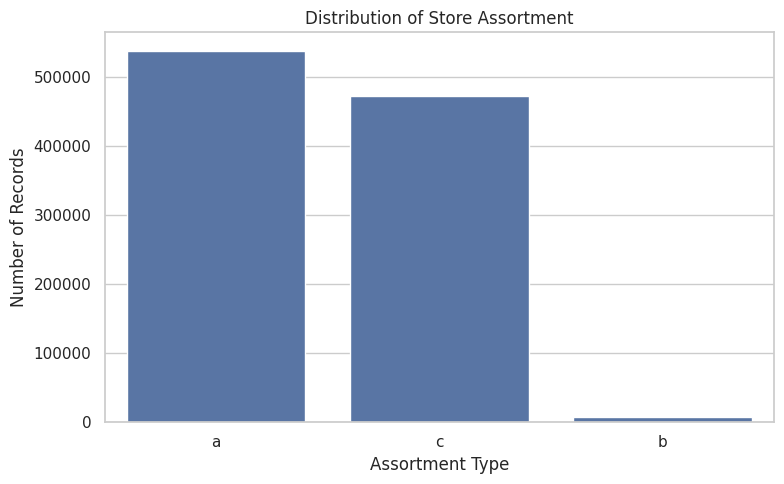

In [ ]:
# SECTION 5.5 - ASSORTMENT DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.countplot(
    data=eda_df,
    x="assortment",
    order=eda_df["assortment"].value_counts().index
)

plt.title("Distribution of Store Assortment")
plt.xlabel("Assortment Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

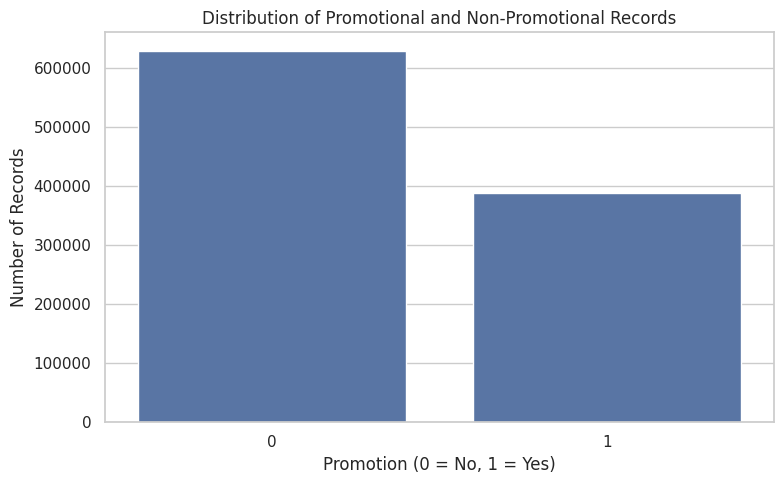

In [ ]:
# SECTION 5.6 - PROMOTION DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.countplot(
    data=eda_df,
    x="promo"
)

plt.title("Distribution of Promotional and Non-Promotional Records")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

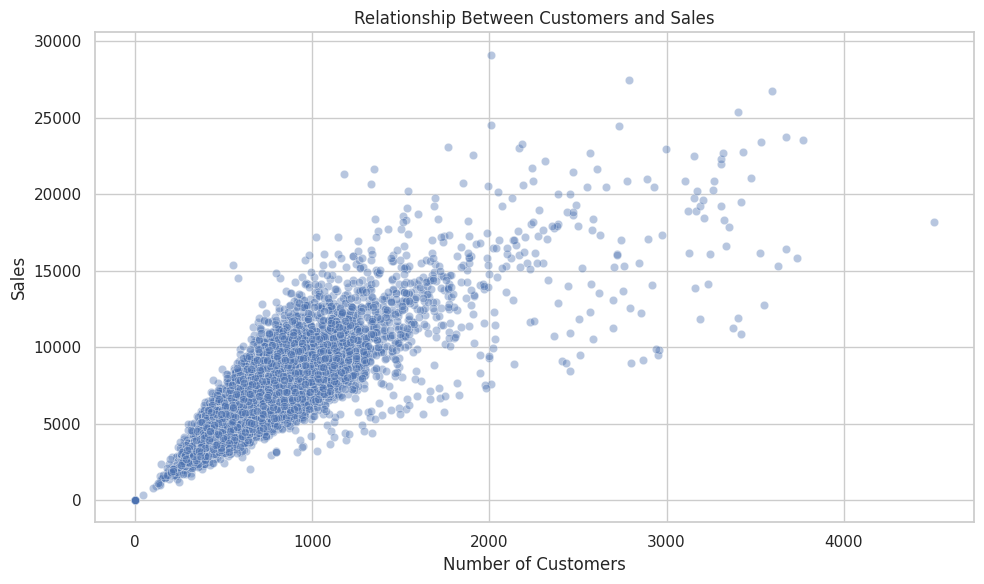

In [ ]:
# SECTION 6.1 - SALES VS CUSTOMERS

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=eda_df.sample(10000, random_state=42),
    x="customers",
    y="sales",
    alpha=0.4
)

plt.title("Relationship Between Customers and Sales")
plt.xlabel("Number of Customers")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

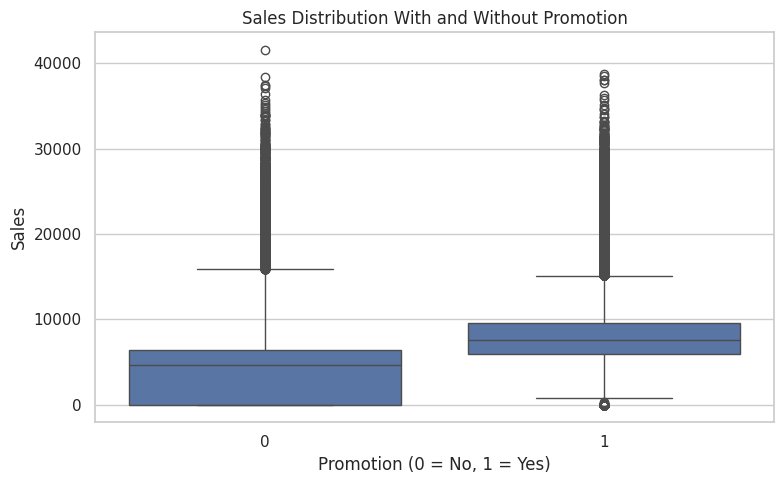

In [ ]:
# SECTION 6.2 - SALES VS PROMOTION

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="promo",
    y="sales"
)

plt.title("Sales Distribution With and Without Promotion")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

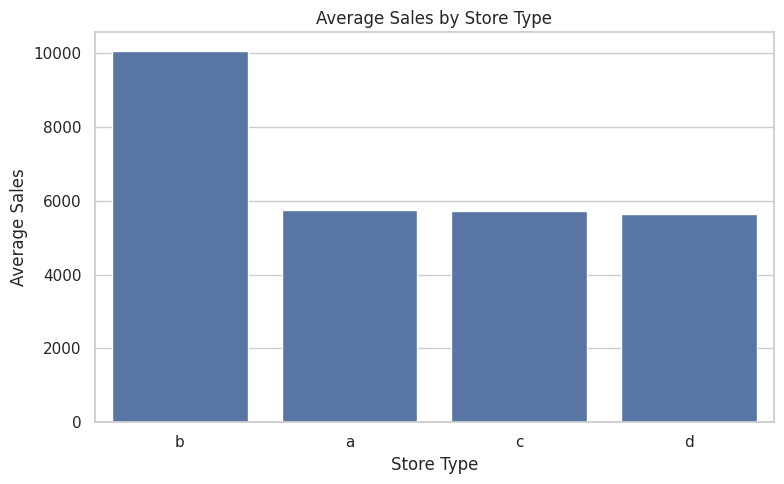

,storetype,sales
0,b,10058.84
1,a,5738.18
2,c,5723.63
3,d,5641.82


In [ ]:
# SECTION 6.3 - SALES BY STORE TYPE

storetype_sales = (
    eda_df.groupby("storetype")["sales"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=storetype_sales,
    x="storetype",
    y="sales"
)

plt.title("Average Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

display(storetype_sales)

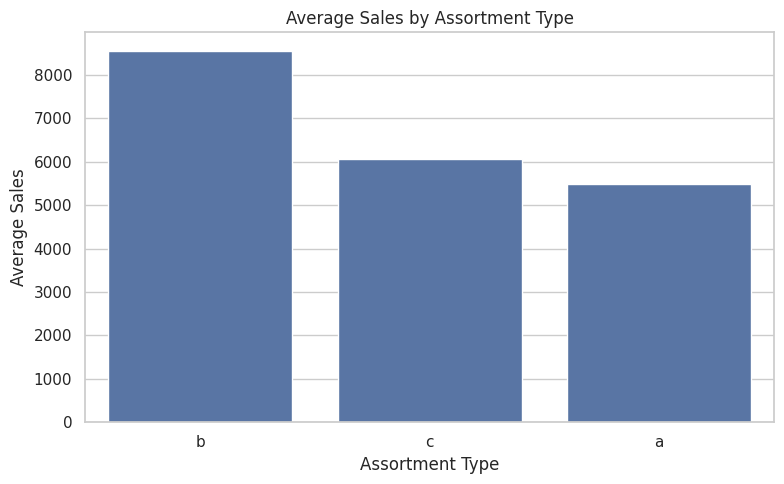

,assortment,sales
0,b,8553.93
1,c,6058.68
2,a,5481.03


In [ ]:
# SECTION 6.4 - SALES BY ASSORTMENT

assortment_sales = (
    eda_df.groupby("assortment")["sales"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=assortment_sales,
    x="assortment",
    y="sales"
)

plt.title("Average Sales by Assortment Type")
plt.xlabel("Assortment Type")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

display(assortment_sales)

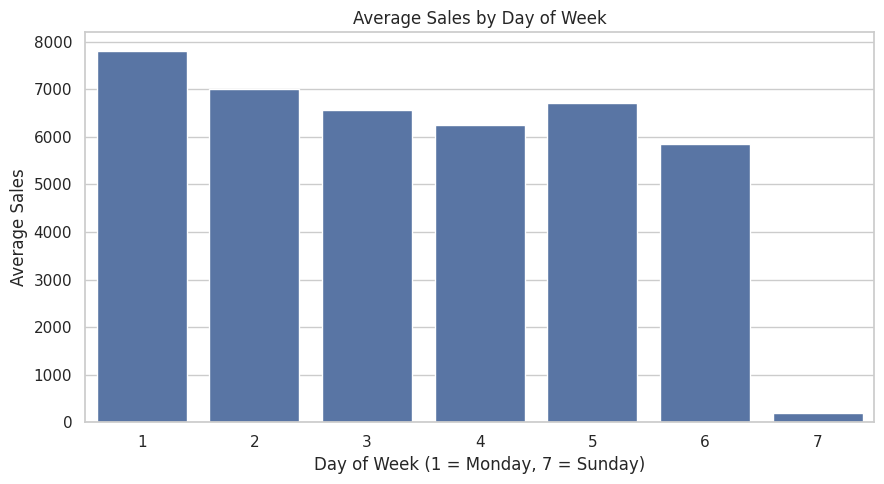

,dayofweek,sales
0,1,7809.04
1,2,7005.24
2,3,6555.88
3,4,6247.58
4,5,6723.27
5,6,5847.56
6,7,204.18


In [ ]:
# SECTION 6.5 - SALES BY DAY OF WEEK

weekday_sales = (
    eda_df.groupby("dayofweek")["sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=weekday_sales,
    x="dayofweek",
    y="sales"
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week (1 = Monday, 7 = Sunday)")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

display(weekday_sales)

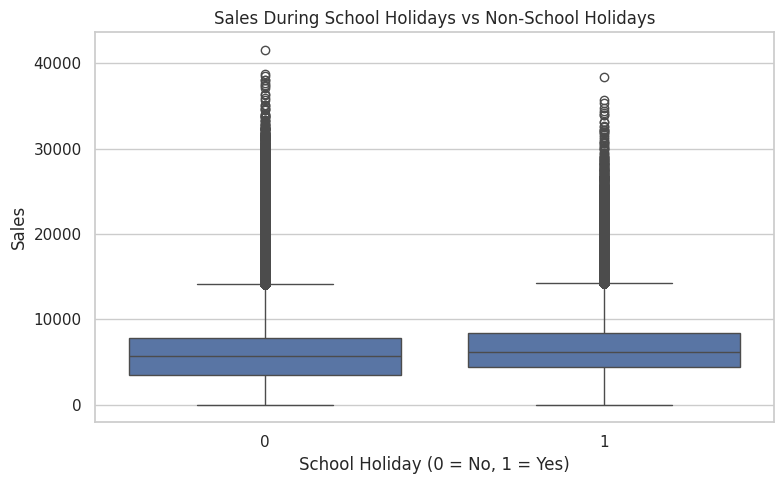

In [ ]:
# SECTION 6.6 - SALES VS SCHOOL HOLIDAY

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="schoolholiday",
    y="sales"
)

plt.title("Sales During School Holidays vs Non-School Holidays")
plt.xlabel("School Holiday (0 = No, 1 = Yes)")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

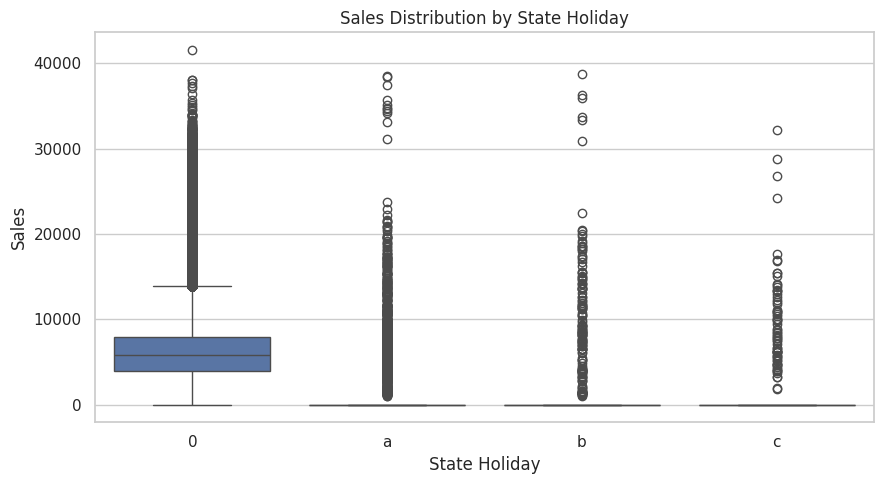

In [ ]:
# SECTION 6.7 - SALES VS STATE HOLIDAY

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=eda_df,
    x="stateholiday",
    y="sales"
)

plt.title("Sales Distribution by State Holiday")
plt.xlabel("State Holiday")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

In [ ]:
# Select relevant numerical columns for correlation analysis

correlation_columns = [
    "sales",
    "customers",
    "dayofweek",
    "promo",
    "schoolholiday",
    "competitiondistance",
    "promo2"
]

# Keep only columns available in the dataset
correlation_columns = [
    col for col in correlation_columns
    if col in eda_df.columns
]

# Consider only open stores
open_stores_df = eda_df[eda_df["open"] == 1].copy()

correlation_data = open_stores_df[correlation_columns]

print("Selected Columns:")
print(correlation_columns)

print("\nCorrelation Data Shape:", correlation_data.shape)

Selected Columns:
['sales', 'customers', 'dayofweek', 'promo', 'schoolholiday', 'competitiondistance', 'promo2']

Correlation Data Shape: (844392, 7)


In [ ]:
# Calculate Pearson correlation

correlation_matrix = correlation_data.corr()

display(correlation_matrix)

,sales,customers,dayofweek,promo,schoolholiday,competitiondistance,promo2
sales,1.00,0.82,-0.18,0.37,0.04,-0.04,-0.13
customers,0.82,1.00,-0.10,0.18,0.02,-0.15,-0.20
dayofweek,-0.18,-0.10,1.00,-0.29,-0.14,0.01,-0.00
promo,0.37,0.18,-0.29,1.00,0.03,-0.00,-0.00
schoolholiday,0.04,0.02,-0.14,0.03,1.00,-0.00,-0.01
competitiondistance,-0.04,-0.15,0.01,-0.00,-0.00,1.00,-0.14
promo2,-0.13,-0.20,-0.00,-0.00,-0.01,-0.14,1.00


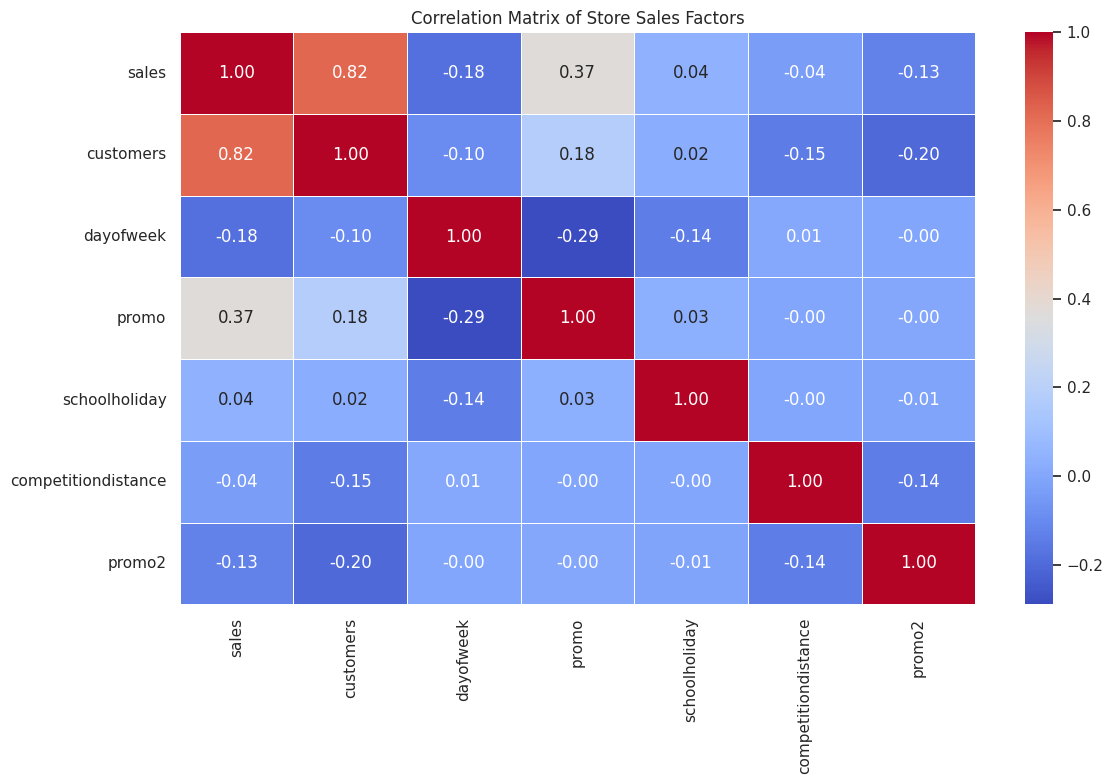

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Store Sales Factors")
plt.tight_layout()
plt.show()

In [ ]:
# Get correlation values with Sales

sales_correlation = (
    correlation_matrix["sales"]
    .drop("sales")
    .sort_values(ascending=False)
)

display(sales_correlation.to_frame(name="Correlation with Sales"))

,Correlation with Sales
customers,0.82
promo,0.37
schoolholiday,0.04
competitiondistance,-0.04
promo2,-0.13
dayofweek,-0.18


In [ ]:
# Extract time-based features

eda_df["year"] = eda_df["date"].dt.year
eda_df["month"] = eda_df["date"].dt.month
eda_df["day"] = eda_df["date"].dt.day
eda_df["day_name"] = eda_df["date"].dt.day_name()

# Display date-related columns

display(
    eda_df[["date", "year", "month", "day", "day_name"]].head()
)

,date,year,month,day,day_name
0,2015-07-31,2015,7,31,Friday
1,2015-07-31,2015,7,31,Friday
2,2015-07-31,2015,7,31,Friday
3,2015-07-31,2015,7,31,Friday
4,2015-07-31,2015,7,31,Friday


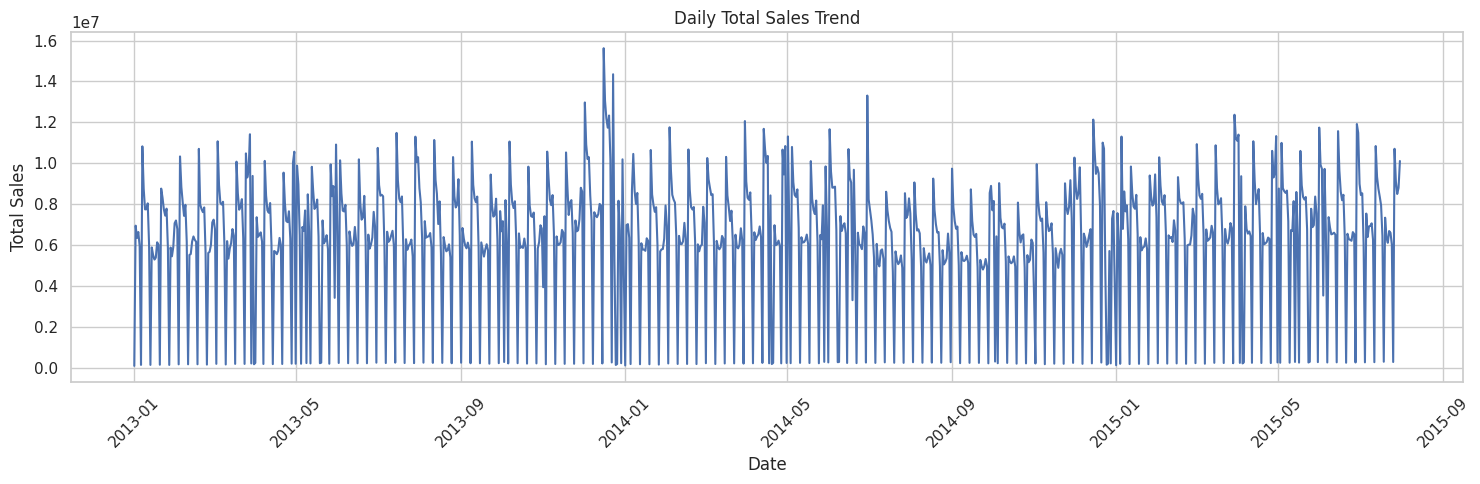

In [ ]:
# Calculate daily total sales

daily_sales = (
    eda_df.groupby("date")["sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(15, 5))

sns.lineplot(
    data=daily_sales,
    x="date",
    y="sales"
)

plt.title("Daily Total Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

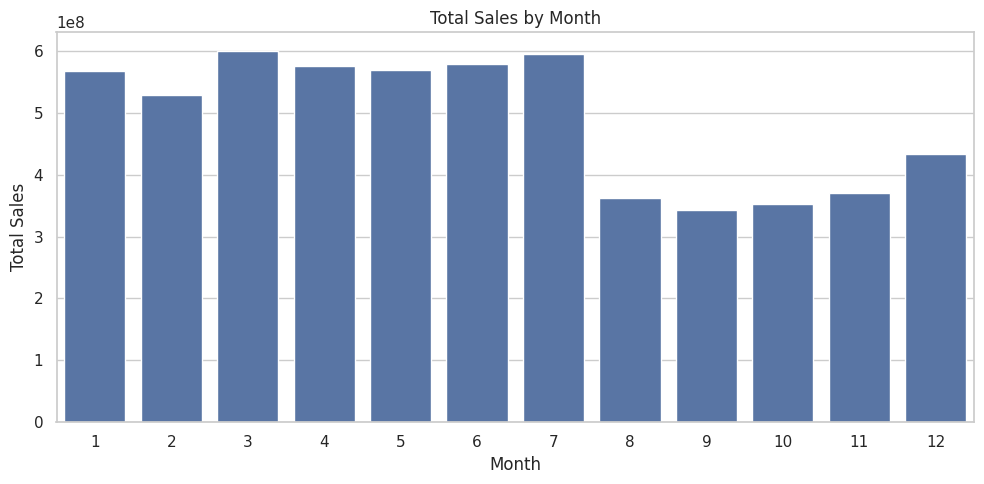

,month,sales
0,1,566728724
1,2,528734410
2,3,599831906
3,4,575895295
4,5,569248217
5,6,578112775
6,7,595059205
7,8,361791202
8,9,342570131
9,10,351878728


In [ ]:
# Calculate monthly total sales

monthly_sales = (
    eda_df.groupby("month")["sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_sales,
    x="month",
    y="sales"
)

plt.title("Total Sales by Month")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

display(monthly_sales)

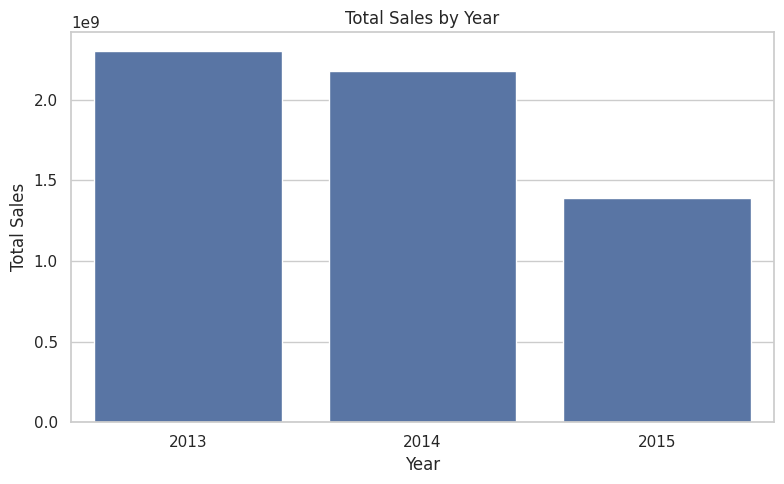

,year,sales
0,2013,2302876084
1,2014,2180804896
2,2015,1389499643


In [ ]:
# Calculate yearly total sales

yearly_sales = (
    eda_df.groupby("year")["sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=yearly_sales,
    x="year",
    y="sales"
)

plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

display(yearly_sales)

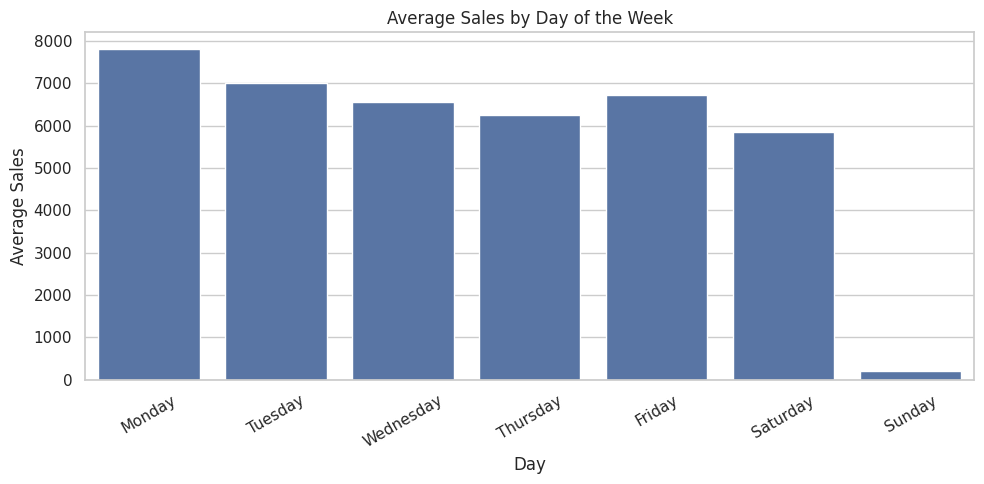

,day_name,sales
0,Monday,7809.04
1,Tuesday,7005.24
2,Wednesday,6555.88
3,Thursday,6247.58
4,Friday,6723.27
5,Saturday,5847.56
6,Sunday,204.18


In [ ]:
# Calculate average sales by weekday

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    eda_df.groupby("day_name")["sales"]
    .mean()
    .reindex(weekday_order)
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_sales,
    x="day_name",
    y="sales"
)

plt.title("Average Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(weekday_sales)

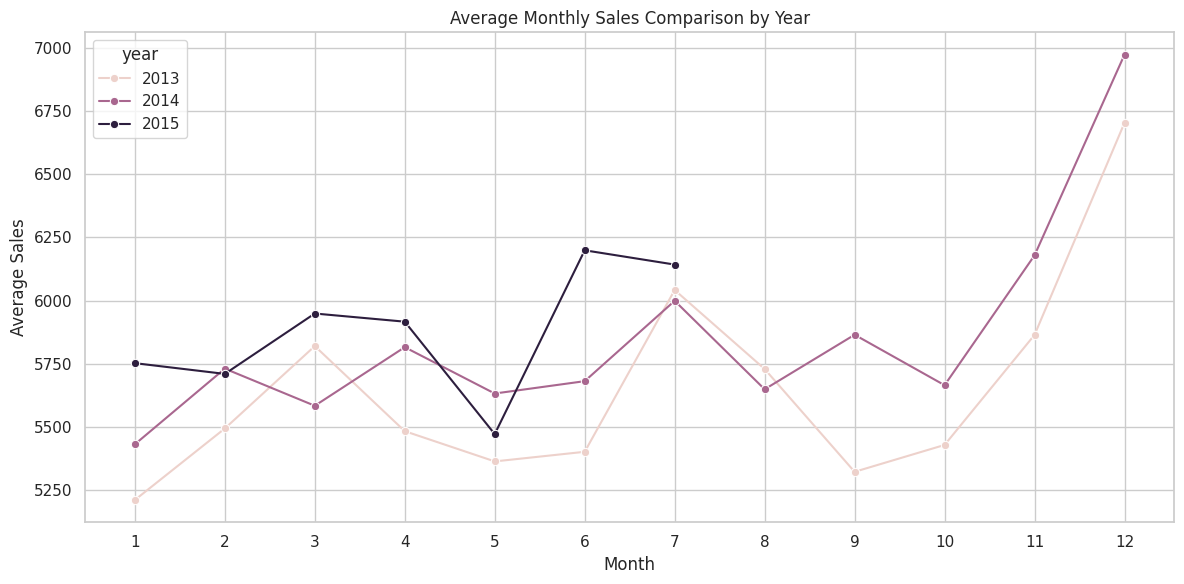

In [ ]:
# Calculate average sales for each month and year

monthly_yearly_sales = (
    eda_df.groupby(["year", "month"])["sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_yearly_sales,
    x="month",
    y="sales",
    hue="year",
    marker="o"
)

plt.title("Average Monthly Sales Comparison by Year")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [ ]:
# Consider only open stores for sales performance analysis

open_stores_df = eda_df[eda_df["open"] == 1].copy()

print("Original Dataset Shape:", eda_df.shape)
print("Open Stores Dataset Shape:", open_stores_df.shape)

Original Dataset Shape: (1017209, 25)
Open Stores Dataset Shape: (844392, 25)


,mean,median,sum,count
storetype,,,,
b,10231.41,9130.00,159231395,15563
c,6932.51,6407.00,783221426,112978
a,6925.17,6285.00,3165334859,457077
d,6822.14,6395.00,1765392943,258774


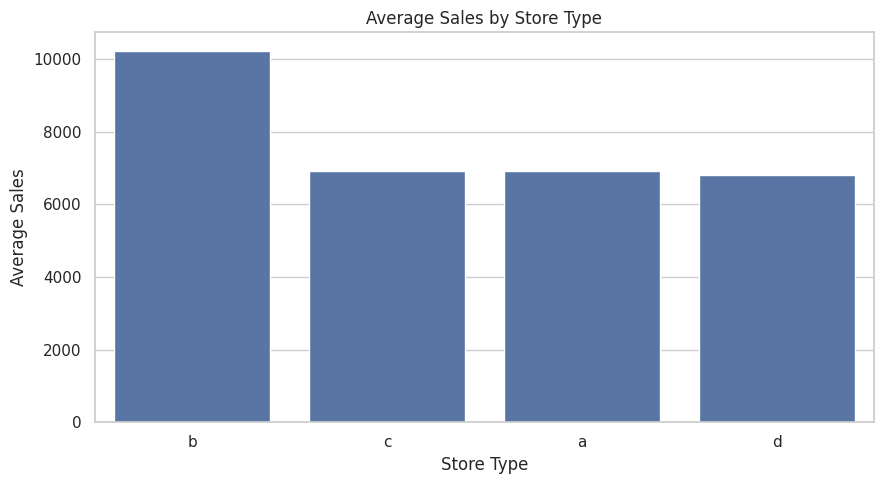

In [ ]:
storetype_analysis = (
    open_stores_df.groupby("storetype")["sales"]
    .agg(["mean", "median", "sum", "count"])
    .sort_values("mean", ascending=False)
)

display(storetype_analysis)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=storetype_analysis.reset_index(),
    x="storetype",
    y="mean"
)

plt.title("Average Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

,mean,median,sum,count
assortment,,,,
b,8639.35,8081.00,70946312,8212
c,7300.53,6675.00,2856484241,391271
a,6621.02,6082.00,2945750070,444909


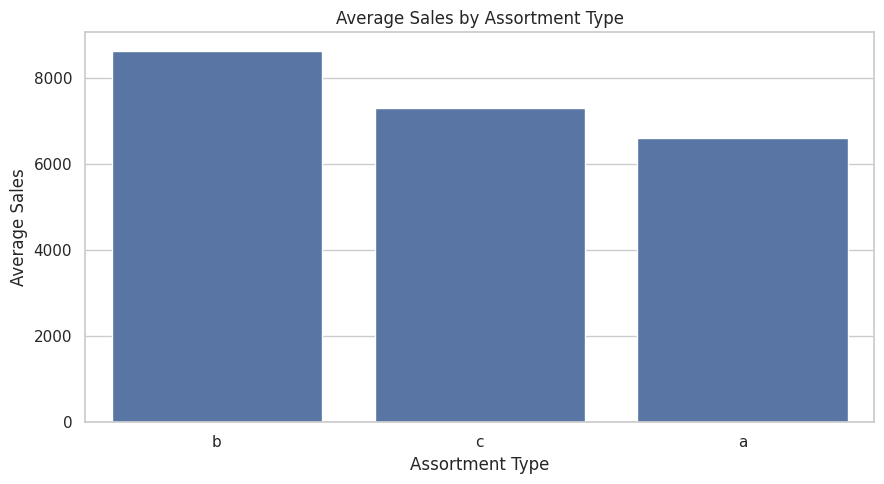

In [ ]:
assortment_analysis = (
    open_stores_df.groupby("assortment")["sales"]
    .agg(["mean", "median", "sum", "count"])
    .sort_values("mean", ascending=False)
)

display(assortment_analysis)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=assortment_analysis.reset_index(),
    x="assortment",
    y="mean"
)

plt.title("Average Sales by Assortment Type")
plt.xlabel("Assortment Type")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

,mean,median,sum,count
promo,,,,
0,5929.41,5459.00,2771974337,467496
1,8228.28,7649.00,3101206286,376896


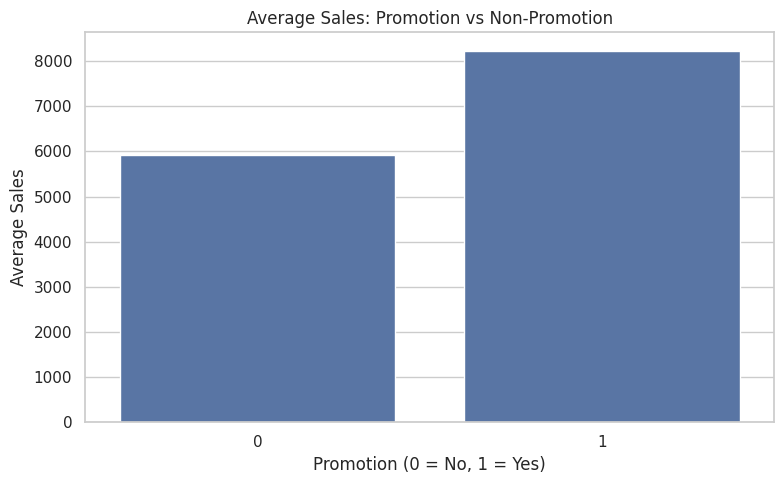

In [ ]:
promo_analysis = (
    open_stores_df.groupby("promo")["sales"]
    .agg(["mean", "median", "sum", "count"])
)

display(promo_analysis)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=promo_analysis.reset_index(),
    x="promo",
    y="mean"
)

plt.title("Average Sales: Promotion vs Non-Promotion")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

,mean,median,sum,count
schoolholiday,,,,
0,6896.78,6326.00,4696260531,680935
1,7200.18,6562.00,1176920092,163457


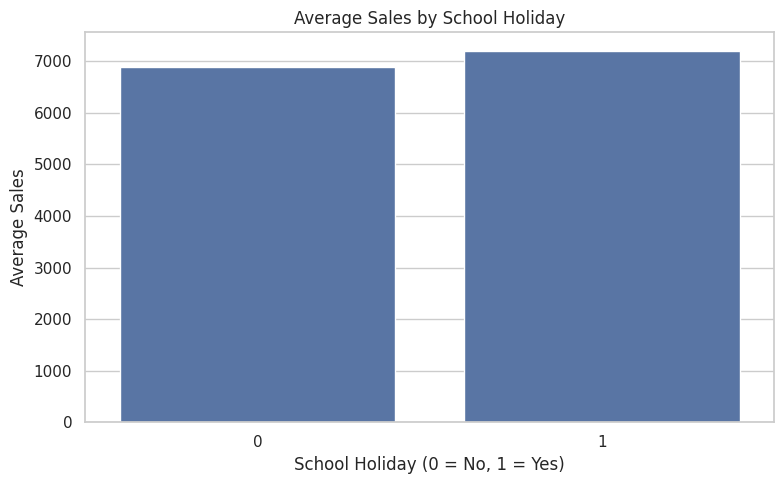

In [ ]:
schoolholiday_analysis = (
    open_stores_df.groupby("schoolholiday")["sales"]
    .agg(["mean", "median", "sum", "count"])
)

display(schoolholiday_analysis)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=schoolholiday_analysis.reset_index(),
    x="schoolholiday",
    y="mean"
)

plt.title("Average Sales by School Holiday")
plt.xlabel("School Holiday (0 = No, 1 = Yes)")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

,mean,median,sum,count
stateholiday,,,,
b,9887.89,8423.00,1433744,145
c,9743.75,8397.00,691806,71
a,8487.47,7556.00,5890305,694
0,6992.16,6400.00,5113659442,731342
0,6701.49,6163.00,751505326,112140


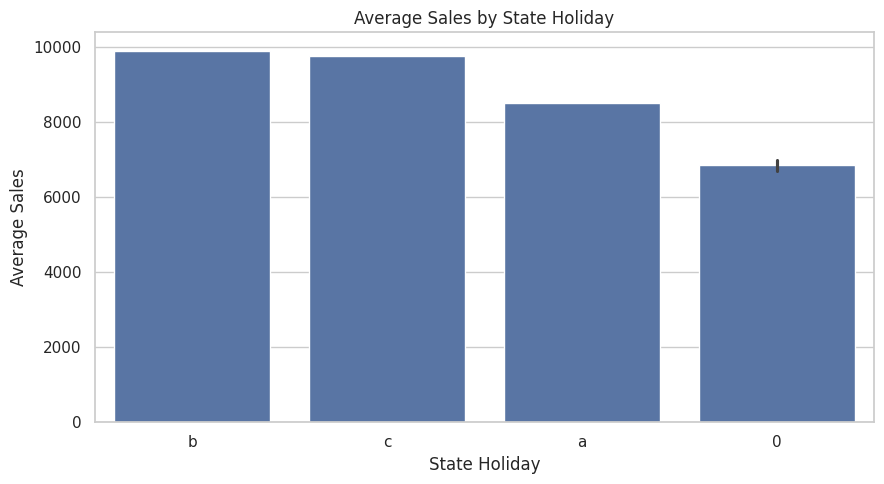

In [ ]:
stateholiday_analysis = (
    open_stores_df.groupby("stateholiday")["sales"]
    .agg(["mean", "median", "sum", "count"])
    .sort_values("mean", ascending=False)
)

display(stateholiday_analysis)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=stateholiday_analysis.reset_index(),
    x="stateholiday",
    y="mean"
)

plt.title("Average Sales by State Holiday")
plt.xlabel("State Holiday")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

,store,average_sales
0,817,21757.48
1,262,20718.52
2,1114,20666.56
3,251,19123.07
4,842,18574.80
5,513,18179.09
6,562,17969.56
7,788,17961.91
8,383,17294.72
9,756,16574.82


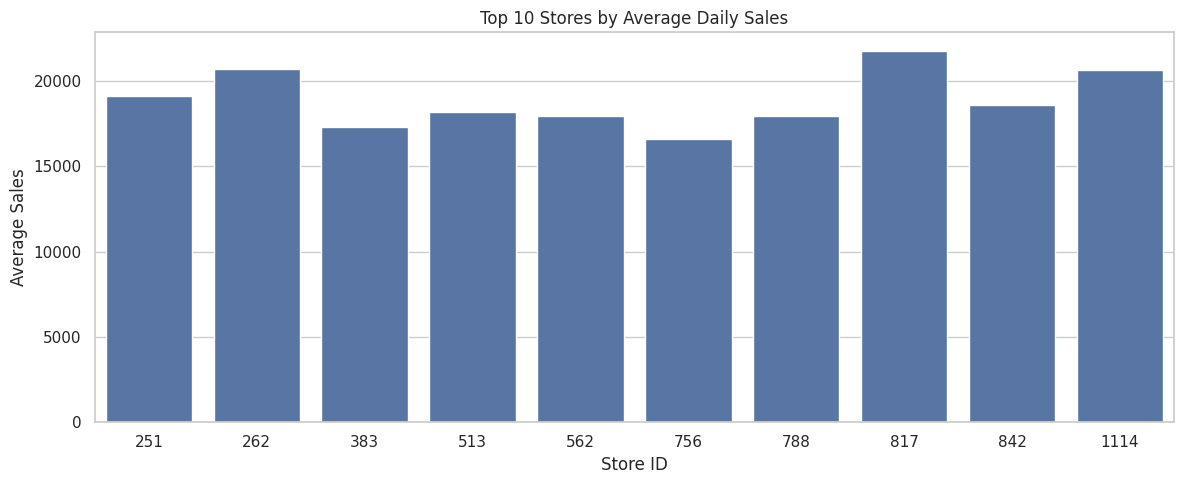

In [ ]:
top_stores = (
    open_stores_df.groupby("store")["sales"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="average_sales")
)

display(top_stores)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=top_stores,
    x="store",
    y="average_sales"
)

plt.title("Top 10 Stores by Average Daily Sales")
plt.xlabel("Store ID")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

,store,average_sales
0,307,2703.74
1,543,2790.38
2,198,2900.60
3,208,2936.29
4,841,2972.61
5,254,3005.98
6,794,3083.81
7,219,3133.71
8,210,3193.98
9,425,3237.66


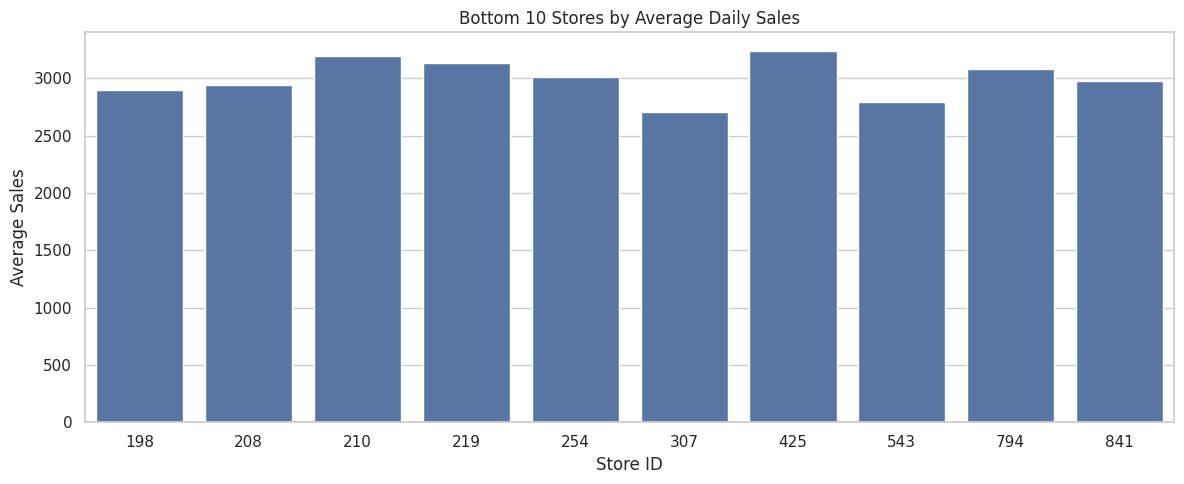

In [ ]:
bottom_stores = (
    open_stores_df.groupby("store")["sales"]
    .mean()
    .sort_values(ascending=True)
    .head(10)
    .reset_index(name="average_sales")
)

display(bottom_stores)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=bottom_stores,
    x="store",
    y="average_sales"
)

plt.title("Bottom 10 Stores by Average Daily Sales")
plt.xlabel("Store ID")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

In [ ]:
# Calculate important business metrics

total_sales = eda_df["sales"].sum()
average_sales = eda_df["sales"].mean()
total_customers = eda_df["customers"].sum()
average_customers = eda_df["customers"].mean()

total_stores = eda_df["store"].nunique()

print("BUSINESS PERFORMANCE SUMMARY")
print("=" * 45)

print(f"Total Sales: {total_sales:,.0f}")
print(f"Average Daily Sales: {average_sales:,.2f}")
print(f"Total Customer Records: {total_customers:,.0f}")
print(f"Average Daily Customers: {average_customers:,.2f}")
print(f"Total Stores: {total_stores}")

BUSINESS PERFORMANCE SUMMARY
Total Sales: 5,873,180,623
Average Daily Sales: 5,773.82
Total Customer Records: 644,041,755
Average Daily Customers: 633.15
Total Stores: 1115


In [ ]:
promo_insight = (
    open_stores_df.groupby("promo")["sales"]
    .mean()
)

sales_without_promo = promo_insight.get(0, np.nan)
sales_with_promo = promo_insight.get(1, np.nan)

promo_difference = sales_with_promo - sales_without_promo

promo_percentage = (
    (promo_difference / sales_without_promo) * 100
    if sales_without_promo != 0 else np.nan
)

print("PROMOTION PERFORMANCE")
print("=" * 40)

print(f"Average Sales Without Promotion: {sales_without_promo:,.2f}")
print(f"Average Sales With Promotion: {sales_with_promo:,.2f}")
print(f"Sales Difference: {promo_difference:,.2f}")
print(f"Percentage Difference: {promo_percentage:.2f}%")

PROMOTION PERFORMANCE
Average Sales Without Promotion: 5,929.41
Average Sales With Promotion: 8,228.28
Sales Difference: 2,298.87
Percentage Difference: 38.77%


In [ ]:
promo_insight = (
    open_stores_df.groupby("promo")["sales"]
    .mean()
)

sales_without_promo = promo_insight.get(0, np.nan)
sales_with_promo = promo_insight.get(1, np.nan)

promo_difference = sales_with_promo - sales_without_promo

promo_percentage = (
    (promo_difference / sales_without_promo) * 100
    if sales_without_promo != 0 else np.nan
)

print("PROMOTION PERFORMANCE")
print("=" * 40)

print(f"Average Sales Without Promotion: {sales_without_promo:,.2f}")
print(f"Average Sales With Promotion: {sales_with_promo:,.2f}")
print(f"Sales Difference: {promo_difference:,.2f}")
print(f"Percentage Difference: {promo_percentage:.2f}%")


PROMOTION PERFORMANCE
Average Sales Without Promotion: 5,929.41
Average Sales With Promotion: 8,228.28
Sales Difference: 2,298.87
Percentage Difference: 38.77%


In [ ]:
best_store_type = (
    open_stores_df.groupby("storetype")["sales"]
    .mean()
    .sort_values(ascending=False)
)

print("STORE TYPE PERFORMANCE")
print("=" * 40)

print(best_store_type)

print("\nBest Performing Store Type:", best_store_type.index[0])
print("Highest Average Sales:", round(best_store_type.iloc[0], 2))

STORE TYPE PERFORMANCE
storetype
b   10231.41
c    6932.51
a    6925.17
d    6822.14
Name: sales, dtype: float64

Best Performing Store Type: b
Highest Average Sales: 10231.41


In [ ]:
monthly_insight = (
    eda_df.groupby("month")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print("MONTHLY SALES PERFORMANCE")
print("=" * 40)

print(monthly_insight)

print("\nBest Performing Month:", monthly_insight.index[0])
print("Highest Monthly Sales:", round(monthly_insight.iloc[0], 2))

MONTHLY SALES PERFORMANCE
month
3     599831906
7     595059205
6     578112775
4     575895295
5     569248217
1     566728724
2     528734410
12    433831153
11    369498877
8     361791202
10    351878728
9     342570131
Name: sales, dtype: int64

Best Performing Month: 3
Highest Monthly Sales: 599831906


In [ ]:
customer_sales_correlation = (
    open_stores_df["customers"].corr(open_stores_df["sales"])
)

print("CUSTOMER AND SALES RELATIONSHIP")
print("=" * 40)

print(f"Correlation: {customer_sales_correlation:.3f}")

CUSTOMER AND SALES RELATIONSHIP
Correlation: 0.824


In [ ]:
print("=" * 65)
print("BUSINESS INSIGHTS AND RECOMMENDATIONS")
print("=" * 65)

print("\nINSIGHT 1: PROMOTION PERFORMANCE")

if promo_percentage > 0:
    print(f"Sales are {promo_percentage:.2f}% higher during promotional periods.")
    print("Recommendation: Evaluate successful promotions and use them strategically.")
elif promo_percentage < 0:
    print(f"Sales are {abs(promo_percentage):.2f}% lower during promotional periods.")
    print("Recommendation: Review promotion timing, discounts, and product selection.")
else:
    print("Promotion periods show no clear difference in average sales.")
    print("Recommendation: Evaluate promotion effectiveness using product-level data.")

print("\nINSIGHT 2: STORE TYPE PERFORMANCE")

print(f"Store Type {best_store_type.index[0]} has the highest average sales.")
print("Recommendation: Study its product assortment, customer demand, and operating practices.")

print("\nINSIGHT 3: MONTHLY SALES PERFORMANCE")

print(f"Month {monthly_insight.index[0]} has the highest total sales.")
print("Recommendation: Plan inventory and staffing according to monthly demand patterns.")

print("\nINSIGHT 4: CUSTOMER AND SALES RELATIONSHIP")

print(f"Customer-Sales correlation: {customer_sales_correlation:.3f}")

if customer_sales_correlation > 0:
    print("Recommendation: Monitor customer traffic and improve customer retention.")
else:
    print("Recommendation: Investigate other factors influencing sales performance.")

print("=" * 65)

BUSINESS INSIGHTS AND RECOMMENDATIONS

INSIGHT 1: PROMOTION PERFORMANCE
Sales are 38.77% higher during promotional periods.
Recommendation: Evaluate successful promotions and use them strategically.

INSIGHT 2: STORE TYPE PERFORMANCE
Store Type b has the highest average sales.
Recommendation: Study its product assortment, customer demand, and operating practices.

INSIGHT 3: MONTHLY SALES PERFORMANCE
Month 3 has the highest total sales.
Recommendation: Plan inventory and staffing according to monthly demand patterns.

INSIGHT 4: CUSTOMER AND SALES RELATIONSHIP
Customer-Sales correlation: 0.824
Recommendation: Monitor customer traffic and improve customer retention.


In [ ]:
import os

os.makedirs("outputs/visualizations", exist_ok=True)
os.makedirs("reports", exist_ok=True)

print("Output folders created successfully.")

Output folders created successfully.


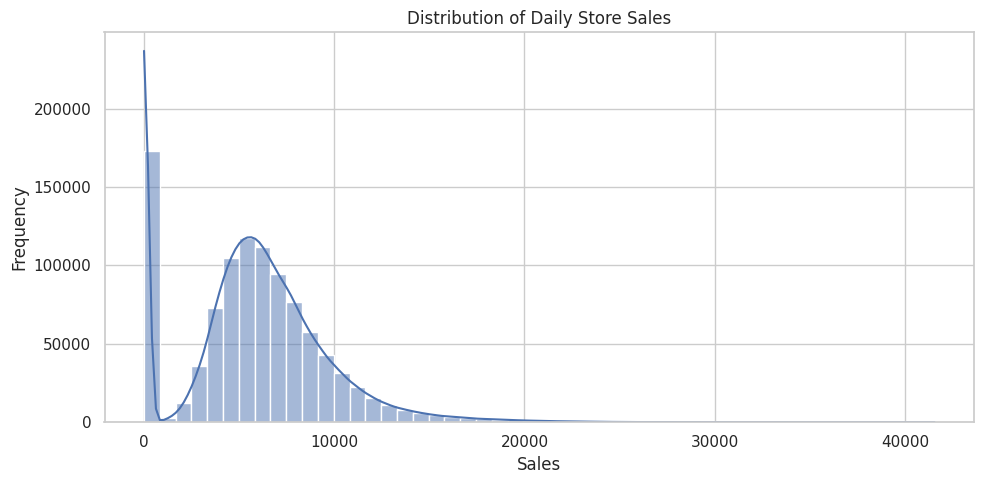

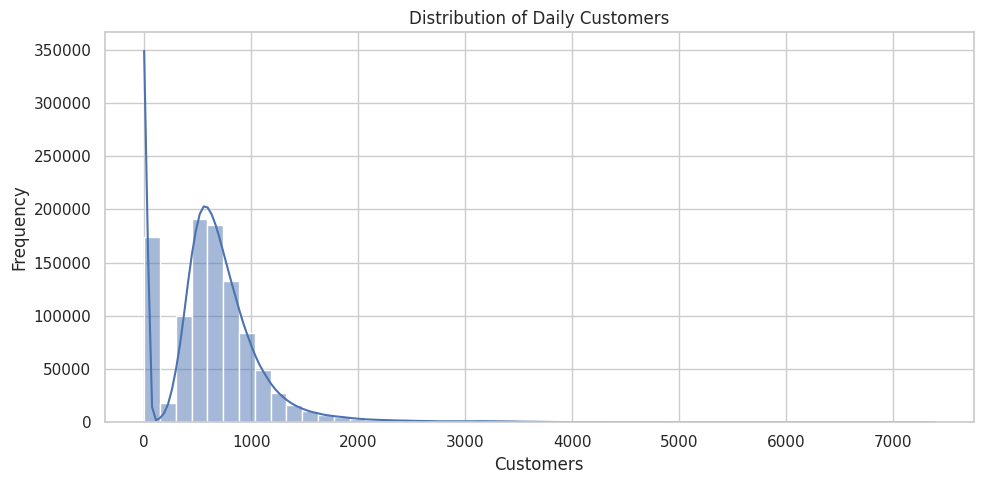

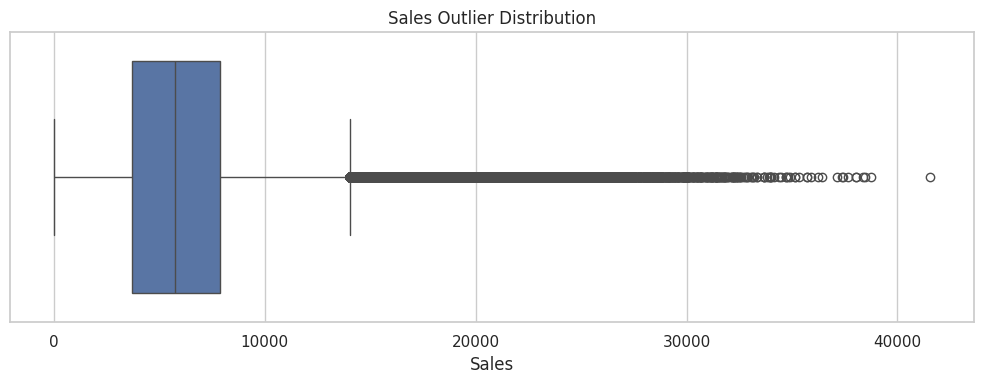

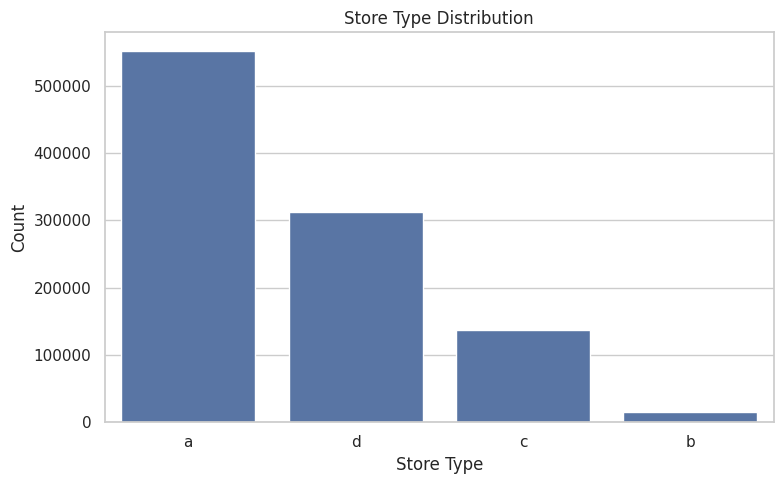

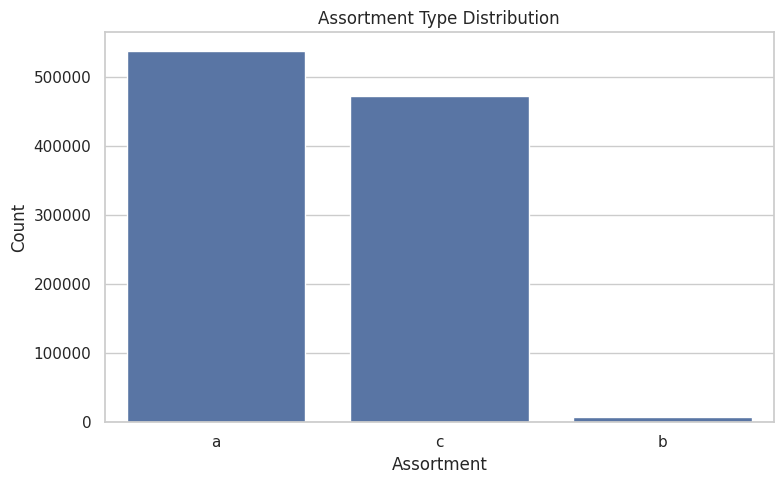

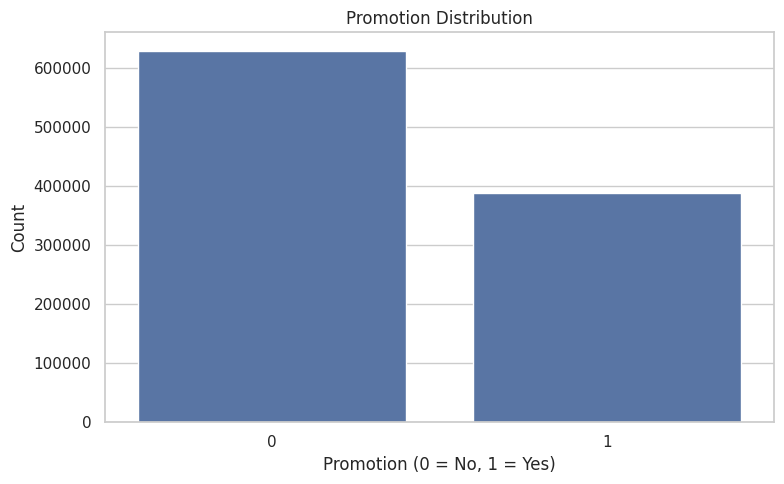

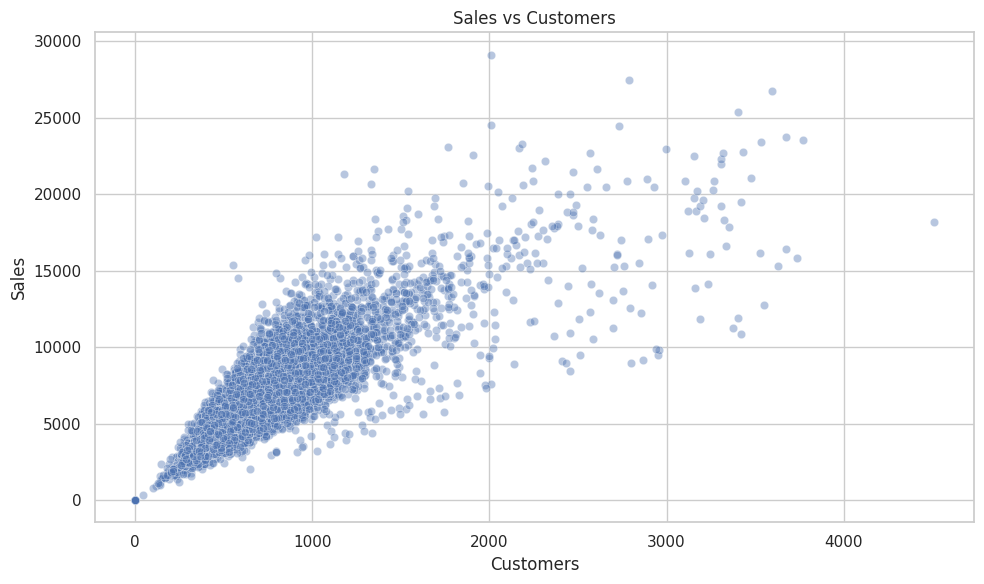

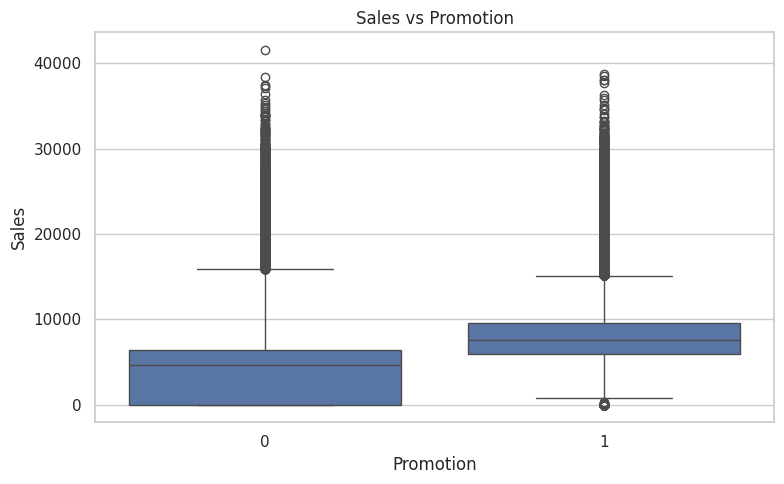

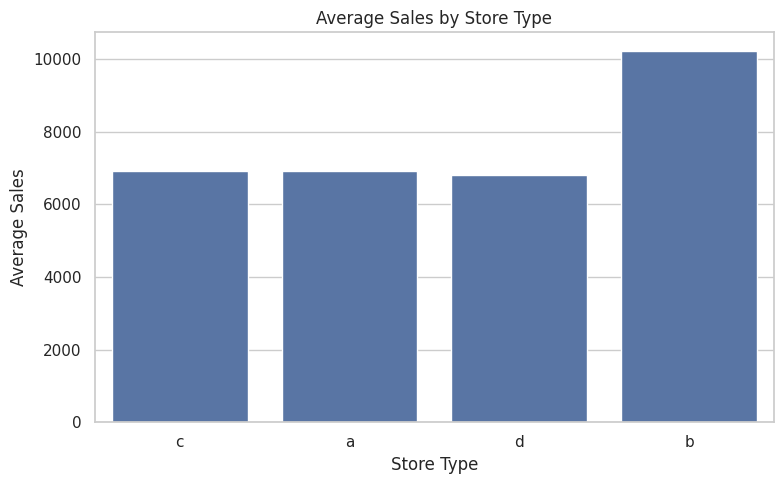

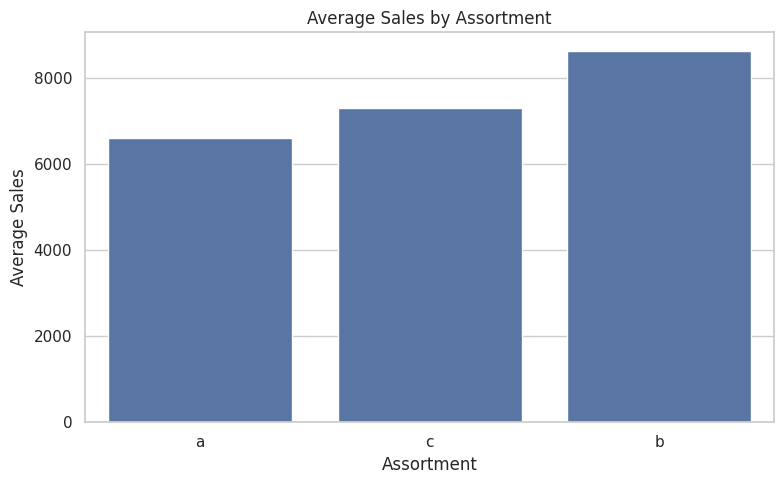

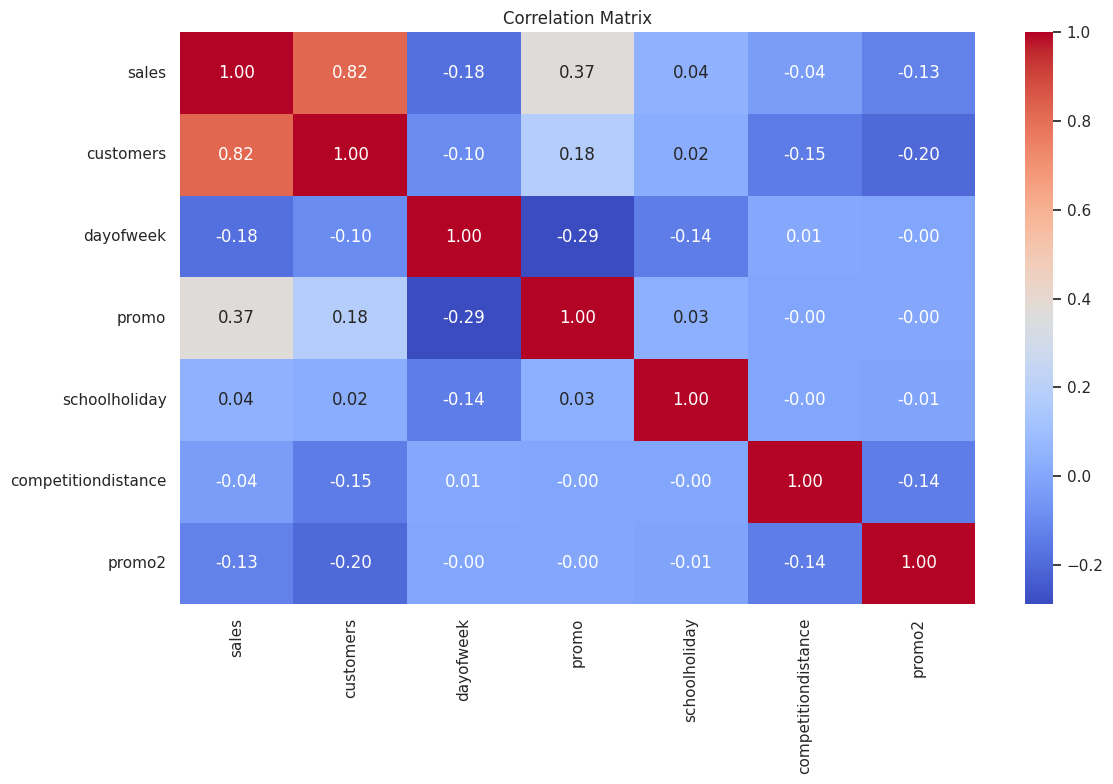

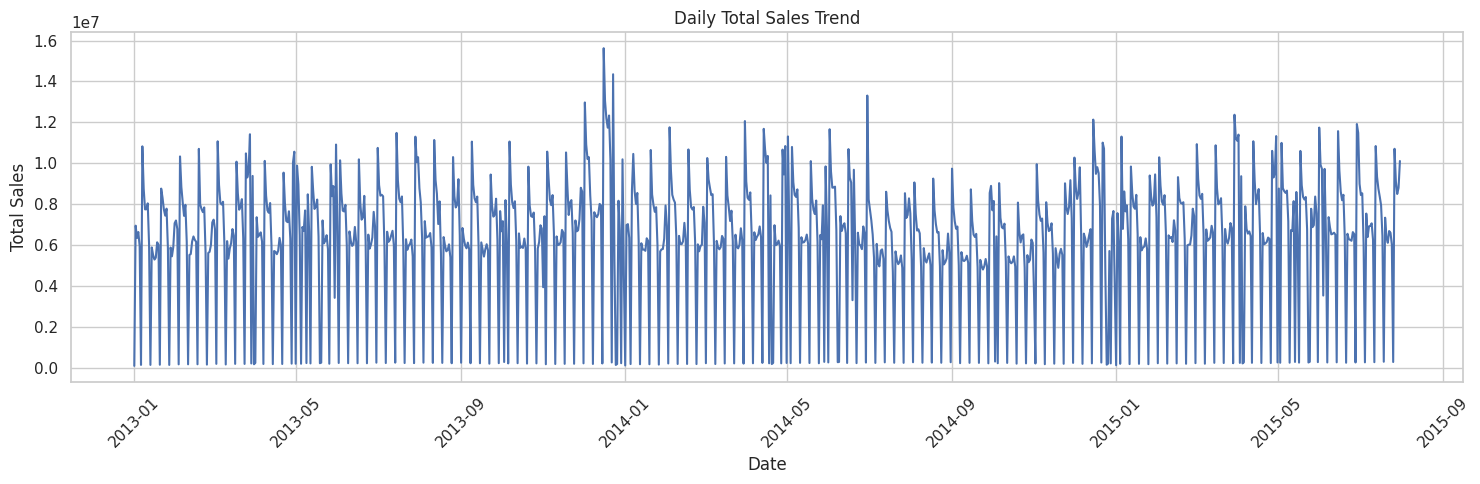

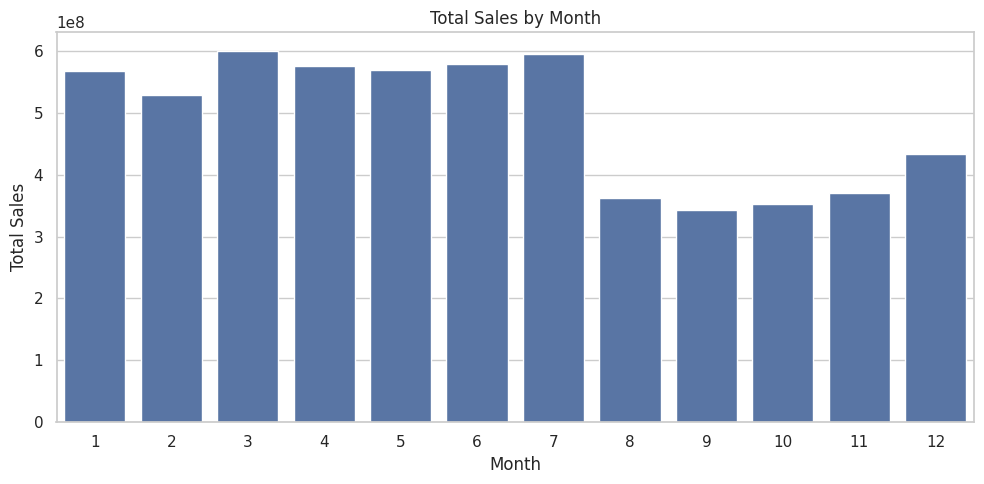

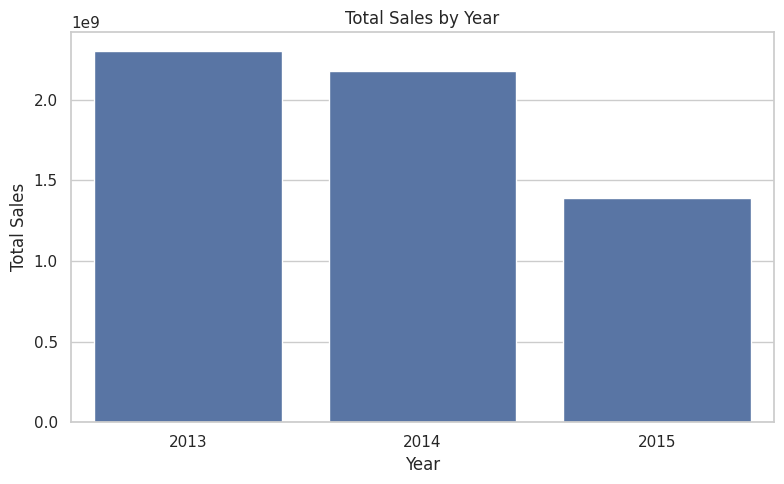

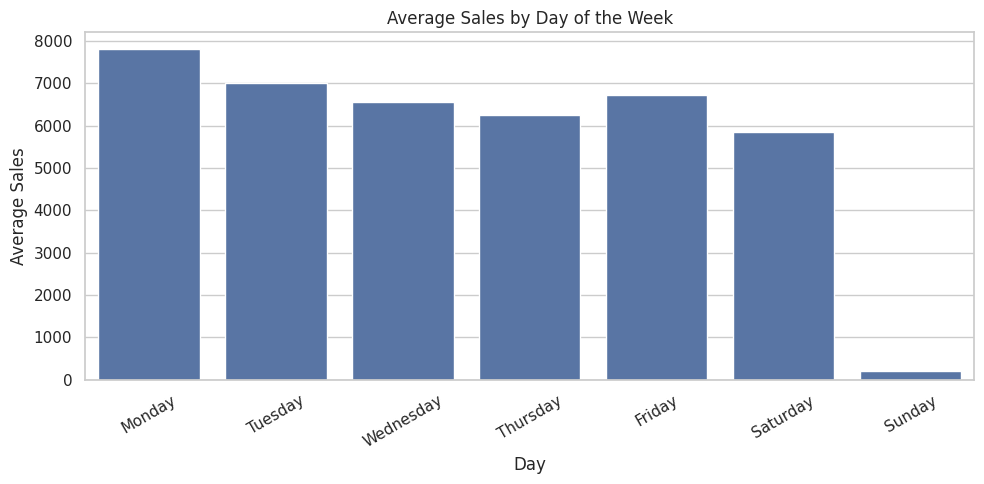

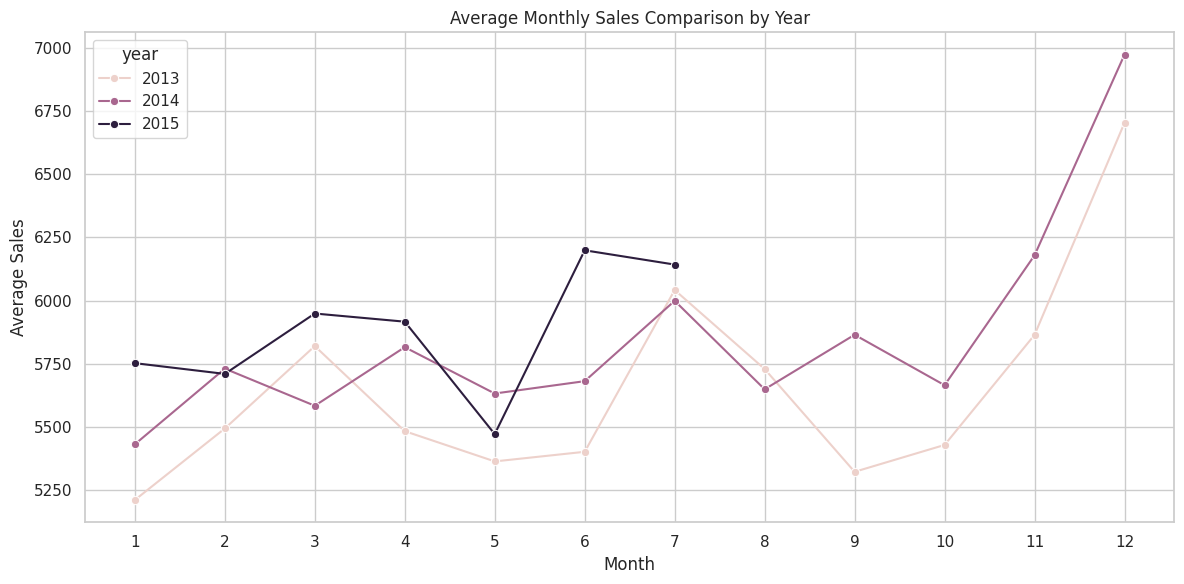

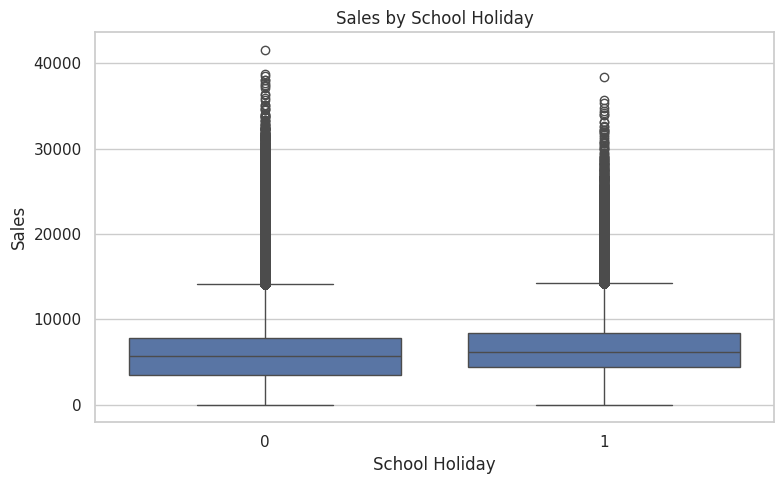

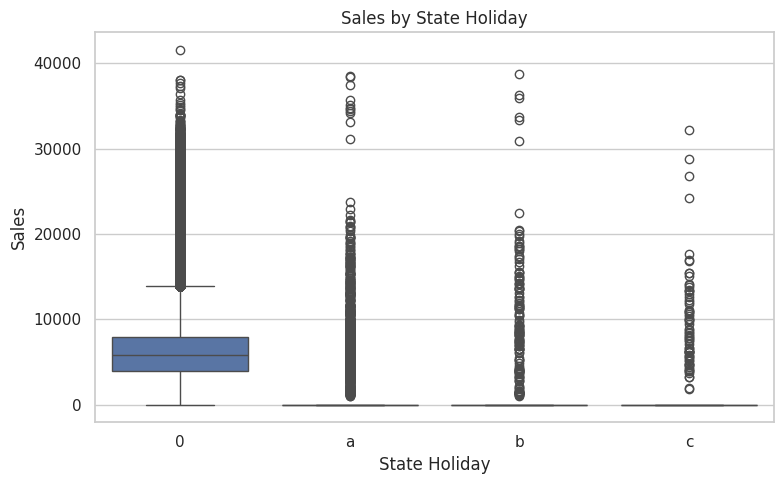

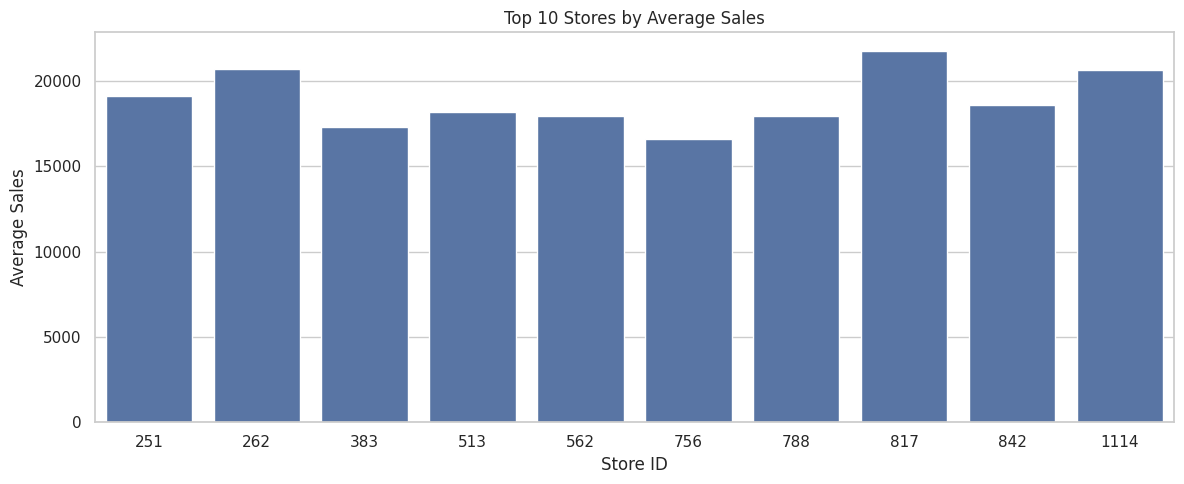

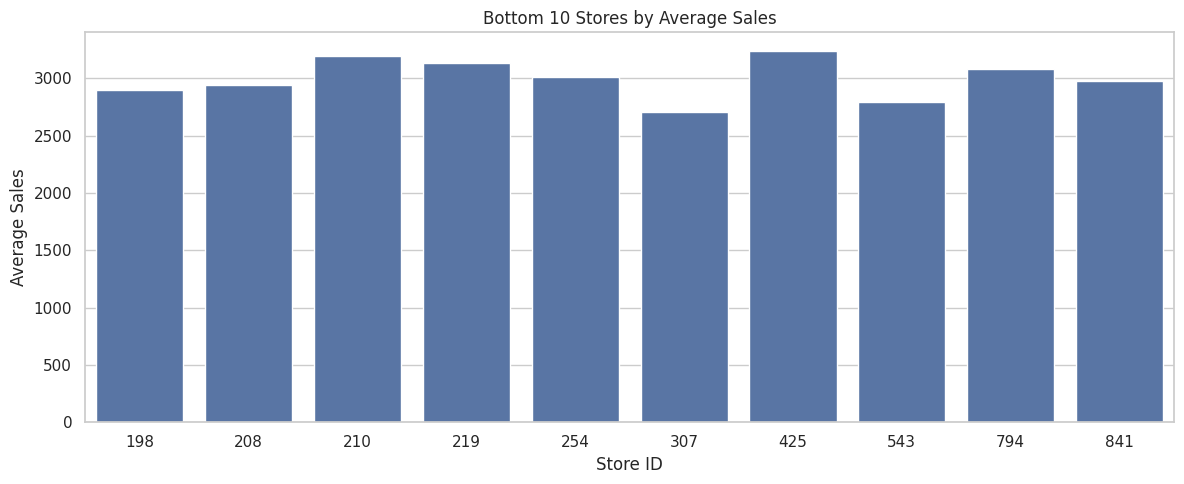


ALL EDA VISUALIZATIONS SAVED SUCCESSFULLY

Total Visualizations: 20

Saved Files:
01_sales_distribution.png
02_customers_distribution.png
03_sales_boxplot.png
04_storetype_distribution.png
05_assortment_distribution.png
06_promotion_distribution.png
07_sales_vs_customers.png
08_sales_vs_promotion.png
09_sales_by_storetype.png
10_sales_by_assortment.png
11_correlation_heatmap.png
12_daily_sales_trend.png
13_monthly_sales.png
14_yearly_sales.png
15_weekday_sales.png
16_monthly_sales_by_year.png
17_sales_by_schoolholiday.png
18_sales_by_stateholiday.png
19_top_10_stores.png
20_bottom_10_stores.png


In [ ]:
# ================================================
# SAVE ALL EDA VISUALIZATIONS
# ================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create visualization folder
os.makedirs("outputs/visualizations", exist_ok=True)

# Use open stores for relevant sales comparisons
open_stores_df = eda_df[eda_df["open"] == 1].copy()


# 1. SALES DISTRIBUTION
plt.figure(figsize=(10, 5))
sns.histplot(data=eda_df, x="sales", bins=50, kde=True)
plt.title("Distribution of Daily Store Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("outputs/visualizations/01_sales_distribution.png", dpi=300)
plt.show()


# 2. CUSTOMERS DISTRIBUTION
plt.figure(figsize=(10, 5))
sns.histplot(data=eda_df, x="customers", bins=50, kde=True)
plt.title("Distribution of Daily Customers")
plt.xlabel("Customers")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("outputs/visualizations/02_customers_distribution.png", dpi=300)
plt.show()


# 3. SALES BOXPLOT
plt.figure(figsize=(10, 4))
sns.boxplot(x=eda_df["sales"])
plt.title("Sales Outlier Distribution")
plt.xlabel("Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/03_sales_boxplot.png", dpi=300)
plt.show()


# 4. STORE TYPE DISTRIBUTION
plt.figure(figsize=(8, 5))
sns.countplot(data=eda_df, x="storetype",
              order=eda_df["storetype"].value_counts().index)
plt.title("Store Type Distribution")
plt.xlabel("Store Type")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("outputs/visualizations/04_storetype_distribution.png", dpi=300)
plt.show()


# 5. ASSORTMENT DISTRIBUTION
plt.figure(figsize=(8, 5))
sns.countplot(data=eda_df, x="assortment",
              order=eda_df["assortment"].value_counts().index)
plt.title("Assortment Type Distribution")
plt.xlabel("Assortment")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("outputs/visualizations/05_assortment_distribution.png", dpi=300)
plt.show()


# 6. PROMOTION DISTRIBUTION
plt.figure(figsize=(8, 5))
sns.countplot(data=eda_df, x="promo")
plt.title("Promotion Distribution")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("outputs/visualizations/06_promotion_distribution.png", dpi=300)
plt.show()


# 7. SALES VS CUSTOMERS
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=eda_df.sample(10000, random_state=42),
    x="customers", y="sales", alpha=0.4
)
plt.title("Sales vs Customers")
plt.xlabel("Customers")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/07_sales_vs_customers.png", dpi=300)
plt.show()


# 8. SALES VS PROMOTION
plt.figure(figsize=(8, 5))
sns.boxplot(data=eda_df, x="promo", y="sales")
plt.title("Sales vs Promotion")
plt.xlabel("Promotion")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/08_sales_vs_promotion.png", dpi=300)
plt.show()


# 9. AVERAGE SALES BY STORE TYPE
plt.figure(figsize=(8, 5))
sns.barplot(data=open_stores_df, x="storetype", y="sales", errorbar=None)
plt.title("Average Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/09_sales_by_storetype.png", dpi=300)
plt.show()


# 10. AVERAGE SALES BY ASSORTMENT
plt.figure(figsize=(8, 5))
sns.barplot(data=open_stores_df, x="assortment", y="sales", errorbar=None)
plt.title("Average Sales by Assortment")
plt.xlabel("Assortment")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/10_sales_by_assortment.png", dpi=300)
plt.show()


# 11. CORRELATION HEATMAP
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("outputs/visualizations/11_correlation_heatmap.png", dpi=300)
plt.show()


# 12. DAILY SALES TREND
plt.figure(figsize=(15, 5))
sns.lineplot(data=daily_sales, x="date", y="sales")
plt.title("Daily Total Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("outputs/visualizations/12_daily_sales_trend.png", dpi=300)
plt.show()


# 13. MONTHLY SALES
plt.figure(figsize=(10, 5))
sns.barplot(data=monthly_sales, x="month", y="sales")
plt.title("Total Sales by Month")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/13_monthly_sales.png", dpi=300)
plt.show()


# 14. YEARLY SALES
plt.figure(figsize=(8, 5))
sns.barplot(data=yearly_sales, x="year", y="sales")
plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/14_yearly_sales.png", dpi=300)
plt.show()


# 15. WEEKDAY SALES
plt.figure(figsize=(10, 5))
sns.barplot(data=weekday_sales, x="day_name", y="sales")
plt.title("Average Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("outputs/visualizations/15_weekday_sales.png", dpi=300)
plt.show()


# 16. MONTHLY SALES COMPARISON BY YEAR
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_yearly_sales,
    x="month", y="sales", hue="year", marker="o"
)
plt.title("Average Monthly Sales Comparison by Year")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.savefig("outputs/visualizations/16_monthly_sales_by_year.png", dpi=300)
plt.show()


# 17. SALES BY SCHOOL HOLIDAY
plt.figure(figsize=(8, 5))
sns.boxplot(data=eda_df, x="schoolholiday", y="sales")
plt.title("Sales by School Holiday")
plt.xlabel("School Holiday")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/17_sales_by_schoolholiday.png", dpi=300)
plt.show()


# 18. SALES BY STATE HOLIDAY
plt.figure(figsize=(8, 5))
sns.boxplot(data=eda_df, x="stateholiday", y="sales")
plt.title("Sales by State Holiday")
plt.xlabel("State Holiday")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/18_sales_by_stateholiday.png", dpi=300)
plt.show()


# 19. TOP 10 STORES
plt.figure(figsize=(12, 5))
sns.barplot(data=top_stores, x="store", y="average_sales")
plt.title("Top 10 Stores by Average Sales")
plt.xlabel("Store ID")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/19_top_10_stores.png", dpi=300)
plt.show()


# 20. BOTTOM 10 STORES
plt.figure(figsize=(12, 5))
sns.barplot(data=bottom_stores, x="store", y="average_sales")
plt.title("Bottom 10 Stores by Average Sales")
plt.xlabel("Store ID")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.savefig("outputs/visualizations/20_bottom_10_stores.png", dpi=300)
plt.show()


print("\n" + "=" * 55)
print("ALL EDA VISUALIZATIONS SAVED SUCCESSFULLY")
print("=" * 55)

print("\nTotal Visualizations:", len(os.listdir("outputs/visualizations")))

print("\nSaved Files:")
for filename in sorted(os.listdir("outputs/visualizations")):
    print(filename)

In [ ]:
eda_report = f"""
ROSSMANN STORE SALES
EXPLORATORY DATA ANALYSIS REPORT
==========================================

1. DATASET OVERVIEW

Total Records: {len(eda_df):,}
Total Stores: {eda_df['store'].nunique()}
Total Columns: {len(eda_df.columns)}

Date Range:
{eda_df['date'].min()} to {eda_df['date'].max()}


2. SALES SUMMARY

Total Sales: {eda_df['sales'].sum():,.2f}
Average Sales: {eda_df['sales'].mean():,.2f}
Median Sales: {eda_df['sales'].median():,.2f}
Maximum Sales: {eda_df['sales'].max():,.2f}


3. CUSTOMER SUMMARY

Average Customers: {eda_df['customers'].mean():,.2f}
Maximum Customers: {eda_df['customers'].max():,.0f}


4. STORE PERFORMANCE

Total Stores: {eda_df['store'].nunique()}

Best Performing Store Type:
{best_store_type.index[0]}

Highest Sales Month:
{monthly_insight.index[0]}


5. PROMOTION ANALYSIS

Average Sales Without Promotion:
{sales_without_promo:,.2f}

Average Sales With Promotion:
{sales_with_promo:,.2f}

Percentage Difference:
{promo_percentage:.2f}%


6. CORRELATION ANALYSIS

Customer-Sales Correlation:
{customer_sales_correlation:.3f}


7. BUSINESS INSIGHTS

- Promotion performance was analysed.
- Store type performance was compared.
- Monthly sales patterns were identified.
- Customer and sales relationships were examined.


8. CONCLUSION

The exploratory analysis identified sales patterns,
store performance differences, promotional trends,
and time-based variations.

These findings can support business decisions
related to inventory planning, promotions,
and store performance improvement.

==========================================
END OF REPORT
"""

report_path = "reports/EDA_Summary_Report.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(eda_report)

print("EDA summary report saved:", report_path)

EDA summary report saved: reports/EDA_Summary_Report.txt


In [ ]:
!pip install reportlab

In [ ]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet

pdf_path = "reports/EDA_Summary_Report.pdf"

document = SimpleDocTemplate(
    pdf_path,
    pagesize=A4
)

styles = getSampleStyleSheet()

story = []

for line in eda_report.split("\n"):
    if line.strip():
        story.append(Paragraph(line.replace("&", "&amp;"), styles["Normal"]))
    else:
        story.append(Spacer(1, 8))

document.build(story)

print("PDF report saved:", pdf_path)

PDF report saved: reports/EDA_Summary_Report.pdf


In [ ]:
for root, directories, files in os.walk("outputs"):
    for file in files:
        print(os.path.join(root, file))

for root, directories, files in os.walk("reports"):
    for file in files:
        print(os.path.join(root, file))

outputs/visualizations/09_sales_by_storetype.png
outputs/visualizations/10_sales_by_assortment.png
outputs/visualizations/13_monthly_sales.png
outputs/visualizations/07_sales_vs_customers.png
outputs/visualizations/05_assortment_distribution.png
outputs/visualizations/08_sales_vs_promotion.png
outputs/visualizations/03_sales_boxplot.png
outputs/visualizations/19_top_10_stores.png
outputs/visualizations/11_correlation_heatmap.png
outputs/visualizations/18_sales_by_stateholiday.png
outputs/visualizations/06_promotion_distribution.png
outputs/visualizations/01_sales_distribution.png
outputs/visualizations/17_sales_by_schoolholiday.png
outputs/visualizations/16_monthly_sales_by_year.png
outputs/visualizations/14_yearly_sales.png
outputs/visualizations/04_storetype_distribution.png
outputs/visualizations/12_daily_sales_trend.png
outputs/visualizations/20_bottom_10_stores.png
outputs/visualizations/02_customers_distribution.png
outputs/visualizations/15_weekday_sales.png
reports/EDA_Summary_

In [ ]:
import os
import zipfile
from google.colab import files

zip_filename = "EDA_Deliverables.zip"

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:

    # Add all visualization images
    for root, dirs, filenames in os.walk("outputs/visualizations"):
        for filename in filenames:
            filepath = os.path.join(root, filename)
            zipf.write(filepath, filepath)

    # Add PDF and TXT reports
    for root, dirs, filenames in os.walk("reports"):
        for filename in filenames:
            filepath = os.path.join(root, filename)
            zipf.write(filepath, filepath)

print("ZIP file created successfully!")
print("Total files:", len(zipf.namelist()) if False else "Check ZIP contents")

# Download ZIP file
files.download(zip_filename)

ZIP file created successfully!
Total files: Check ZIP contents


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>